# Notebook 1: Data Exploration and Preparation

**Project:** Sentiment Analysis of E-Commerce Reviews: Classical ML vs. Transformer (DistilBERT)

**Dataset:** *Women's E-Commerce Clothing Reviews* (Kaggle, uploaded by `nicapotato`, licence CC0: Public Domain)

**What this notebook does**

1. Loads the raw reviews and checks the columns.
2. Cleans the data and turns star ratings into three sentiment classes (negative / neutral / positive).
3. Removes duplicate reviews so the test set cannot contain reviews the model already saw.
4. Explores class balance, review length and common words.
5. Creates **one fixed train / validation / test split** that all four models will share, and saves it to disk.

**How to run:** run the cells from top to bottom (`Runtime > Run all`, or press `Shift+Enter` on each cell).
Nothing in this notebook trains a model; that starts in Phase 2.

## Step 1: Set up the project folder

Colab deletes its files when the session ends, so we keep the project in **Google Drive**.

Before running this cell, upload the whole `ecommerce-sentiment-analysis` folder to
`My Drive` in Google Drive (so the path is `My Drive/ecommerce-sentiment-analysis`).

When you run the cell, Colab will ask permission to connect to your Drive. Click *Allow*.

In [1]:
import os
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    # >>> Change this line ONLY if you put the project folder somewhere else in your Drive <<<
    PROJECT_DIR = Path("/content/drive/MyDrive/ecommerce-sentiment-analysis")
else:
    # Running on your own computer: this notebook lives in <project>/notebooks/
    here = Path.cwd()
    PROJECT_DIR = here.parent if here.name == "notebooks" else here

if not (PROJECT_DIR / "src" / "config.py").exists():
    raise FileNotFoundError(
        f"Could not find the project at {PROJECT_DIR}.\n"
        "Check that the folder 'ecommerce-sentiment-analysis' (containing 'src', 'notebooks', ...) "
        "is in the place named above, or edit PROJECT_DIR."
    )

os.chdir(PROJECT_DIR)                      # work from the project root
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))   # lets us write: from src import config
print("Project folder:", PROJECT_DIR)

Project folder: C:\Users\chand\Downloads\ecommerce-sentiment-analysis-phase1\ecommerce-sentiment-analysis


## Step 2: Import libraries

Colab already has everything Phase 1 needs, so there is nothing to install.
We also import our own two files, `src/config.py` (paths, column names, label mapping) and
`src/data_preprocessing.py` (the reusable functions).

> If you ever edit a file inside `src/`, use `Runtime > Restart session` and run again, otherwise Python keeps using the old version.

In [2]:
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from sklearn.feature_extraction.text import CountVectorizer, ENGLISH_STOP_WORDS

from src import config as C
from src import data_preprocessing as dp

C.ensure_dirs()                       # creates data/, models/, results/ folders if missing
sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 120)

# One fixed colour per class, so charts look consistent across the whole project
PALETTE = {"negative": "#C44E52", "neutral": "#8C8C8C", "positive": "#55A868"}

def savefig(name):
    """Save the current figure into results/figures/ (used later in the report)."""
    path = C.FIGURES_DIR / name
    plt.savefig(path, dpi=150, bbox_inches="tight")
    print("Saved:", path.relative_to(C.PROJECT_DIR))

print("pandas", pd.__version__, "| numpy", np.__version__, "| scikit-learn", sklearn.__version__)

pandas 3.0.2 | numpy 2.4.4 | scikit-learn 1.8.0


## Step 3: Get the dataset and load it

**Dataset facts (from the dataset's own description):**

| Item | Value |
|---|---|
| Name | Women's E-Commerce Clothing Reviews |
| Source | Kaggle, `nicapotato/womens-ecommerce-clothing-reviews` |
| Licence | CC0: Public Domain |
| Size | 23,486 rows |
| Text columns | `Title`, `Review Text` |
| Label column | `Rating` (1 = worst, 5 = best) |

**Download it once:**

1. Open the dataset page on Kaggle (search for *Women's E-Commerce Clothing Reviews* by *nicapotato*) and click **Download**. You may need a free Kaggle account.
2. Put the downloaded `.zip` (or the `.csv` inside it) into `ecommerce-sentiment-analysis/data/raw/` in your Drive.

The next cell finds the file for you (it unzips automatically). If the file is missing and you are on Colab, it will open an upload button so you can pick the file from your computer.

In [3]:
try:
    raw_path = dp.find_raw_file()
except FileNotFoundError:
    if not IN_COLAB:
        raise
    # Colab only: let you upload the file from your computer straight into data/raw/
    from google.colab import files
    print("Dataset not found in data/raw/. Please choose the Kaggle .zip or .csv file:")
    for name, content in files.upload().items():
        (C.RAW_DIR / name).write_bytes(content)
    raw_path = dp.find_raw_file()

print(f"Using file: {raw_path.name}  ({raw_path.stat().st_size / 1e6:.1f} MB)")

Using file: Womens Clothing E-Commerce Reviews.csv  (8.5 MB)


In [4]:
df_raw = dp.load_raw_reviews(raw_path)

print("Shape (rows, columns):", df_raw.shape)
print("Columns:", list(df_raw.columns))
display(df_raw.head(3))
print()
df_raw.info()

Shape (rows, columns): (23486, 11)
Columns: ['Unnamed: 0', 'Clothing ID', 'Age', 'Title', 'Review Text', 'Rating', 'Recommended IND', 'Positive Feedback Count', 'Division Name', 'Department Name', 'Class Name']


,Unnamed: 0,Clothing ID,Age,Title,Review Text,Rating,Recommended IND,Positive Feedback Count,Division Name,Department Name,Class Name
0,0,767,33,NaN,Absolutely wonderful - silky and sexy and comfortable,4,1,0,Initmates,Intimate,Intimates
1,1,1080,34,NaN,"Love this dress! it's sooo pretty. i happened to find it in a store, and i'm glad i did bc i never would have orde...",5,1,4,General,Dresses,Dresses
2,2,1077,60,Some major design flaws,I had such high hopes for this dress and really wanted it to work for me. i initially ordered the petite small (my u...,3,0,0,General,Dresses,Dresses



<class 'pandas.DataFrame'>
RangeIndex: 23486 entries, 0 to 23485
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype
---  ------                   --------------  -----
 0   Unnamed: 0               23486 non-null  int64
 1   Clothing ID              23486 non-null  int64
 2   Age                      23486 non-null  int64
 3   Title                    19676 non-null  str  
 4   Review Text              22641 non-null  str  
 5   Rating                   23486 non-null  int64
 6   Recommended IND          23486 non-null  int64
 7   Positive Feedback Count  23486 non-null  int64
 8   Division Name            23472 non-null  str  
 9   Department Name          23472 non-null  str  
 10  Class Name               23472 non-null  str  
dtypes: int64(6), str(5)
memory usage: 2.0 MB


## Step 4: Check that the columns are what we expect

Our code depends on three columns: `Title`, `Review Text` and `Rating`.
`validate_columns` stops with a clear message if any of them is missing, instead of failing later with a confusing error.

The first column, `Unnamed: 0`, is just a row number created when the file was saved; we ignore it.

In [5]:
optional_present = dp.validate_columns(df_raw)
print("Required columns found:", C.REQUIRED_RAW_COLUMNS)
print("Optional columns found:", optional_present)

ratings_found = sorted(int(r) for r in df_raw[C.RAW_RATING_COL].dropna().unique())
print("Distinct Rating values:", ratings_found)
assert set(ratings_found) <= {1, 2, 3, 4, 5}, "Unexpected rating values: check the file"

Required columns found: ['Title', 'Review Text', 'Rating']
Optional columns found: ['Recommended IND', 'Class Name', 'Department Name', 'Age']
Distinct Rating values: [1, 2, 3, 4, 5]


## Step 5: Missing values

Real data is rarely complete. Let's see how much is missing in each column.

In [6]:
missing = pd.DataFrame({
    "missing": df_raw.isna().sum(),
    "percent": (df_raw.isna().mean() * 100).round(2),
})
display(missing[missing["missing"] > 0])

no_text = df_raw[C.RAW_TEXT_COL].isna()
print(f"Rows with no review text: {int(no_text.sum())} "
      f"({no_text.mean() * 100:.1f}% of all rows); "
      f"{int(df_raw.loc[no_text, C.RAW_TITLE_COL].notna().sum())} of them still have a Title.")

,missing,percent
Title,3810,16.22
Review Text,845,3.60
Division Name,14,0.06
Department Name,14,0.06
Class Name,14,0.06


Rows with no review text: 845 (3.6% of all rows); 1 of them still have a Title.


**Decision:** a review with no text cannot be classified from its text, so we drop those rows.
We use only `Review Text` as the input (not `Title`) to keep the experiment simple and identical for all four models.
(Adding the title is a possible improvement for later.)

## Step 6: Clean the data and create the sentiment labels

`dp.clean_reviews` builds a small, tidy table with four columns:

| Column | Meaning |
|---|---|
| `text` | the review text |
| `rating` | original star rating, 1 to 5 |
| `label` | `negative`, `neutral` or `positive` |
| `label_id` | `0`, `1` or `2` (the numbers the models use) |

**Rating to sentiment mapping**

| Stars | Sentiment | `label_id` |
|---|---|---|
| 1-2 | negative | 0 |
| 3 | neutral | 1 |
| 4-5 | positive | 2 |

**Important limitation:** a star rating is *not* a perfect measure of the sentiment in the text.
Someone may write a glowing review and give 3 stars, or a mixed review about sizing and still give 4.
So our "labels" are *rating-derived labels*, and the models will partly learn that noise.
We will look at this more closely in Step 9.

In [7]:
df, clean_report = dp.clean_reviews(df_raw)
print(clean_report)
display(df.head())

{'rows_in': 23486, 'dropped_missing_text': 845, 'dropped_invalid_rating': 0, 'rows_out': 22641}


,text,rating,label,label_id
0,Absolutely wonderful - silky and sexy and comfortable,4,positive,2
1,"Love this dress! it's sooo pretty. i happened to find it in a store, and i'm glad i did bc i never would have orde...",5,positive,2
2,I had such high hopes for this dress and really wanted it to work for me. i initially ordered the petite small (my u...,3,neutral,1
3,"I love, love, love this jumpsuit. it's fun, flirty, and fabulous! every time i wear it, i get nothing but great comp...",5,positive,2
4,This shirt is very flattering to all due to the adjustable front tie. it is the perfect length to wear with leggings...,5,positive,2


## Step 7: Duplicate reviews (preventing data leakage)

If the same review appears in both the training set and the test set, the model is tested on something it has already seen,
and the score looks better than it really is. This is called **data leakage**.

We check two things:

* **Exact duplicates:** identical text.
* **Near duplicates:** identical after lower-casing and removing punctuation (`"Love it!!"` vs `"love it"`).

If copies of one review have *different* labels, the label is ambiguous, so we drop all of them. Otherwise we keep one copy.

In [8]:
dup_before = dp.duplicate_report(df)
print("Before removing duplicates:", dup_before)

# Look at a few examples
key = df[C.TEXT_COL].map(dp.normalize_for_dedup)
examples = df.loc[key.duplicated(keep=False)].assign(fingerprint=key).sort_values("fingerprint")
if len(examples):
    display(examples[[C.TEXT_COL, C.RATING_COL, C.LABEL_COL]].head(8))
else:
    print("No duplicate reviews found.")

df, dedup_report = dp.drop_duplicates(df)
print("\nAfter removing duplicates:", dedup_report)
print("Remaining duplicates:", dp.duplicate_report(df))

Before removing duplicates: {'rows': 22641, 'exact_duplicate_rows': 7, 'normalized_duplicate_rows': 8, 'groups_with_conflicting_labels': 0}


,text,rating,label
12920,Fits perfect!,5,positive
15087,Fits perfect.,5,positive
9778,"I bought this shirt at the store and after going home and trying it on, i promptly went online and ordered two more!...",5,positive
13763,"I bought this shirt at the store and after going home and trying it on, i promptly went online and ordered two more!...",5,positive
1824,I purchased this and another eva franco dress during retailer's recent 20% off sale. i was looking for dresses that ...,2,negative
12077,I purchased this and another eva franco dress during retailer's recent 20% off sale. i was looking for dresses that ...,2,negative
10332,"Lightweight, soft cotton top and shorts. i think it's meant to be a beach cover-up but i'm wearing it as a thin, lig...",5,positive
10686,"Lightweight, soft cotton top and shorts. i think it's meant to be a beach cover-up but i'm wearing it as a thin, lig...",5,positive



After removing duplicates: {'rows_in': 22641, 'dropped_conflicting_label_rows': 0, 'dropped_duplicate_rows': 8, 'rows_out': 22633}


Remaining duplicates: {'rows': 22633, 'exact_duplicate_rows': 0, 'normalized_duplicate_rows': 0, 'groups_with_conflicting_labels': 0}


Many duplicates are very short reviews such as *"Love it"*; several different customers really did write them.
Removing them is the safe choice: the test set stays honest, at the cost of a few rows.
This only catches duplicates that match after cleaning up punctuation. Reviews that are merely *similar* can still exist, and we keep that in mind when we evaluate in Phase 2.

## Step 8: Class distribution

How many reviews are negative, neutral and positive? If one class is much bigger than the others, the data is **imbalanced**.
This matters because a model can reach a high *accuracy* just by always guessing the biggest class.
That is why this project reports **macro F1-score** (which treats all classes equally) next to accuracy.

,count,percent
label,,
negative,2369,10.5
neutral,2823,12.5
positive,17441,77.1


Imbalance: the biggest class is 7.4x larger than the smallest.
A model that ALWAYS predicts 'positive' would already score 77.1% accuracy.


Saved: results\figures\class_distribution.png


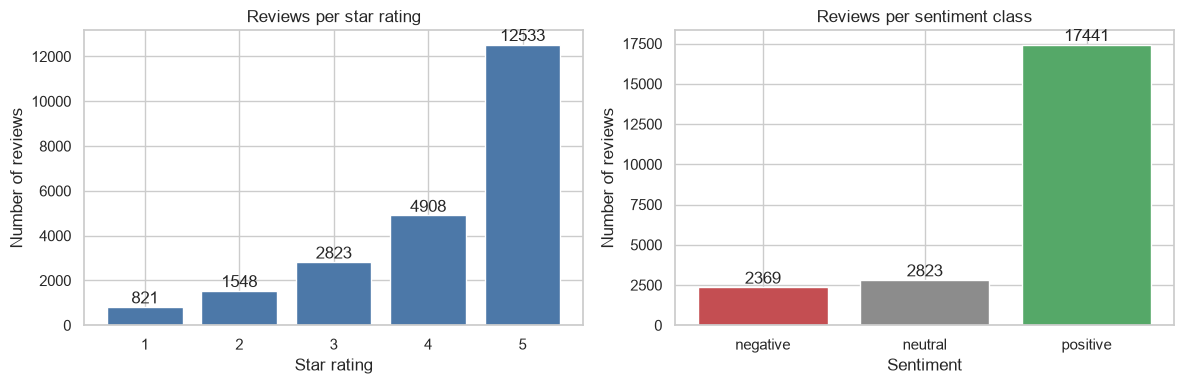

In [9]:
class_counts = df[C.LABEL_COL].value_counts().reindex(C.LABEL_NAMES)
class_table = pd.DataFrame({
    "count": class_counts,
    "percent": (class_counts / len(df) * 100).round(1),
})
display(class_table)
print(f"Imbalance: the biggest class is {class_counts.max() / class_counts.min():.1f}x larger than the smallest.")
print(f"A model that ALWAYS predicts '{class_counts.idxmax()}' would already score "
      f"{class_counts.max() / len(df) * 100:.1f}% accuracy.")

rating_counts = df[C.RATING_COL].value_counts().sort_index()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
bars = axes[0].bar(rating_counts.index.astype(str), rating_counts.values, color="#4C78A8")
axes[0].bar_label(bars)
axes[0].set(title="Reviews per star rating", xlabel="Star rating", ylabel="Number of reviews")

bars = axes[1].bar(class_counts.index, class_counts.values, color=[PALETTE[c] for c in class_counts.index])
axes[1].bar_label(bars)
axes[1].set(title="Reviews per sentiment class", xlabel="Sentiment", ylabel="Number of reviews")

plt.tight_layout()
savefig("class_distribution.png")
plt.show()

Let's also read a few real reviews from each class. Statistics are useful, but you should know what the data actually looks like.

In [10]:
for label in C.LABEL_NAMES:
    subset = df[df[C.LABEL_COL] == label]
    picks = subset.sample(min(3, len(subset)), random_state=C.RANDOM_SEED)
    print(f"--- {label.upper()} ---")
    for _, row in picks.iterrows():
        print(f"  [{row[C.RATING_COL]} stars] {row[C.TEXT_COL][:300]}")
    print()

--- NEGATIVE ---
  [2 stars] This nightgown looked so comfy and cute! i ordered a large and it was so uncomfortably tight.i'm 5'3" and 150lbs. it was such a shame. size large should not just be really a medium!
  [1 stars] Right out of the bag, this top didn't really match the one pictured here (it is the right top, though). the fabric was heavy and felt "damp" -- the way something feels coming out of the wash. very odd.
and the fit is nothing like what's shown on the model. the "v" is not fitted or nicely wrapped (o
  [2 stars] I actually had no problem with the neck hole of this shirt, even with the xs size. however, i had a huge issue with the bottom eyelet section. it's so tight! it stretches across my thighs and looks so funny, as the top part is still loose. i tried moving up to a size small and still had this problem

--- NEUTRAL ---
  [3 stars] I wanted to love this. it is so cute and the xxsp, my usual size, fit perfectly. however there was a fatal flaw in the construction. th

## Step 9: How reliable are rating-based labels?

The dataset has a column `Recommended IND` (1 = the customer recommends the product, 0 = does not).
This gives us a second opinion from the customer. The table shows, for each star rating, what percent of customers recommended the product.

If star ratings were a perfect measure of sentiment, 1-2 stars would be near 0% and 4-5 stars near 100%.
The **3-star** row tells us how "neutral" is really behaving in this dataset.

In [11]:
if "Recommended IND" in df_raw.columns:
    tmp = df_raw.loc[df_raw[C.RAW_TEXT_COL].notna(), [C.RAW_RATING_COL, "Recommended IND"]]
    recommend_pct = (tmp.groupby(C.RAW_RATING_COL)["Recommended IND"].mean() * 100).round(1)
    display(recommend_pct.to_frame("% who recommend the product"))
else:
    print("Column 'Recommended IND' not in this file; skipping this check.")

,% who recommend the product
Rating,
1,1.8
2,6.1
3,41.4
4,96.7
5,99.8


**How to read it:** the numbers show that rating-derived labels are a reasonable but imperfect proxy for sentiment.
The neutral class is the most mixed, so expect it to be the hardest to predict.
We will check whether that expectation is true once the models are trained, not before.

## Step 10: Review length

Why this matters:

* Classical models (TF-IDF) do not care about length much.
* **DistilBERT reads a limited number of tokens** (it can handle at most 512; we will choose a smaller limit to save time and memory).
  We need to know how long reviews are so we can choose that limit sensibly.

Here we count **words** as a rough guide. Real token counts (which are usually a bit higher than word counts) are measured in Phase 3 with the actual tokenizer.

,words per review
count,22633.0
mean,60.2
std,28.5
min,2.0
50%,59.0
90%,98.0
95%,101.0
99%,106.0
max,115.0


,mean,median,max
label,,,
negative,60.9,60.0,111
neutral,64.2,64.0,115
positive,59.5,58.0,115


Reviews longer than 64 words: 44.5%
Reviews longer than 128 words: 0.0%
Reviews longer than 256 words: 0.0%
Reviews with fewer than 3 words: 7


Saved: results\figures\review_length.png


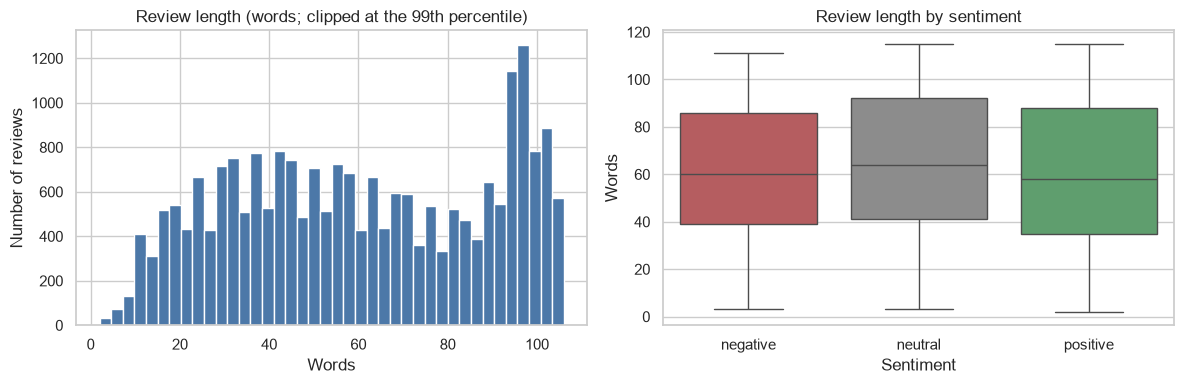

In [12]:
df["word_count"] = df[C.TEXT_COL].str.split().str.len()

display(df["word_count"].describe(percentiles=[0.5, 0.9, 0.95, 0.99]).round(1).to_frame("words per review"))

by_class = df.groupby(C.LABEL_COL)["word_count"].agg(["mean", "median", "max"]).reindex(C.LABEL_NAMES).round(1)
display(by_class)

for limit in (64, 128, 256):
    share = (df["word_count"] > limit).mean() * 100
    print(f"Reviews longer than {limit} words: {share:.1f}%")
print(f"Reviews with fewer than 3 words: {(df['word_count'] < 3).sum()}")

cap = df["word_count"].quantile(0.99)    # clip the x-axis so a few very long reviews do not squash the chart
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(df["word_count"].clip(upper=cap), bins=40, color="#4C78A8")
axes[0].set(title="Review length (words; clipped at the 99th percentile)", xlabel="Words", ylabel="Number of reviews")

sns.boxplot(data=df, x=C.LABEL_COL, y="word_count", order=C.LABEL_NAMES,
            hue=C.LABEL_COL, palette=PALETTE, legend=False, showfliers=False, ax=axes[1])
axes[1].set(title="Review length by sentiment", xlabel="Sentiment", ylabel="Words")

plt.tight_layout()
savefig("review_length.png")
plt.show()

## Step 11: Most common words per class (optional, for understanding)

This chart only helps *us* understand the data; it is not used by the models.
Note that the class sizes differ, so the counts are not directly comparable between charts. Look at *which* words appear.

Saved: results\figures\top_words_per_class.png


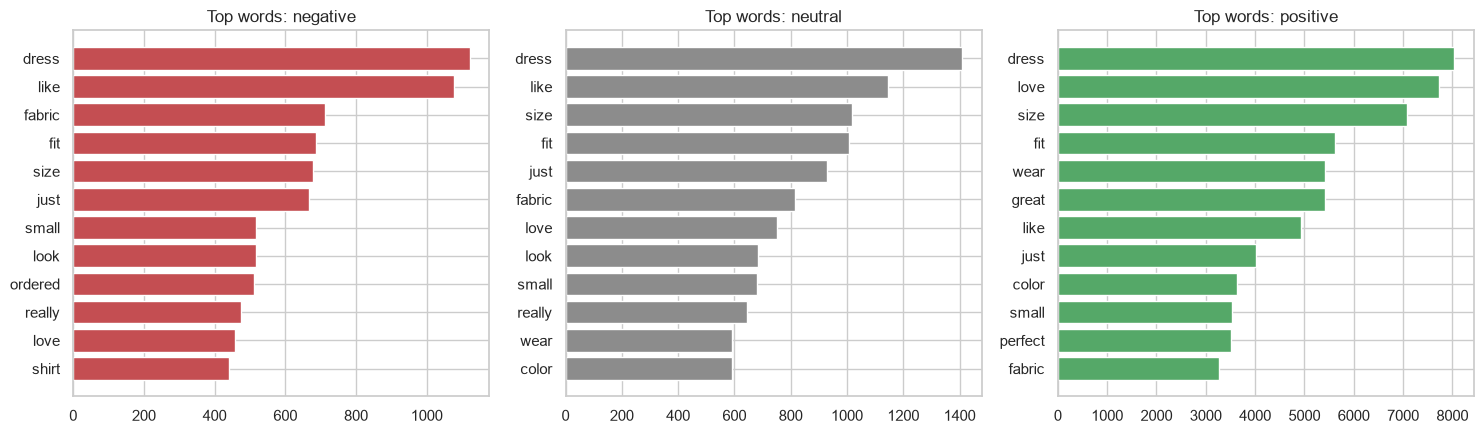

Is 'not' in scikit-learn's English stop-word list? True
Is 'no' in the list? True


In [13]:
def top_words(texts, n=12):
    """Return the n most frequent words (ignoring very common English 'stop words')."""
    vectorizer = CountVectorizer(stop_words="english", min_df=3)
    counts = np.asarray(vectorizer.fit_transform(texts).sum(axis=0)).ravel()
    vocab = np.array(vectorizer.get_feature_names_out())
    order = counts.argsort()[::-1][:n]
    return vocab[order], counts[order]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, label in zip(axes, C.LABEL_NAMES):
    words, counts = top_words(df.loc[df[C.LABEL_COL] == label, C.TEXT_COL])
    ax.barh(words[::-1], counts[::-1], color=PALETTE[label])
    ax.set_title(f"Top words: {label}")
plt.tight_layout()
savefig("top_words_per_class.png")
plt.show()

print("Is 'not' in scikit-learn's English stop-word list?", "not" in ENGLISH_STOP_WORDS)
print("Is 'no' in the list?", "no" in ENGLISH_STOP_WORDS)

**Lesson for Phase 2:** sentiment depends on words like *"not"* ("not good" is the opposite of "good").
If the last cell printed `True`, the standard stop-word list would delete exactly those words,
so for the classical models we will **not** use that list blindly.

## Step 12: Create the train / validation / test split

We split the cleaned data **once** and save it, so every model uses exactly the same examples.

| Split | Share | Purpose |
|---|---|---|
| Train | 70% | the model learns from these |
| Validation | 15% | we use it to make decisions (settings, when to stop DistilBERT training) |
| Test | 15% | touched **only at the end** to report final scores; never used to make decisions |

* **Stratified:** each split keeps the same percentages of negative / neutral / positive reviews.
* **Seed = 42:** running the notebook again gives exactly the same split.
* The TF-IDF vectorizer will later be fitted **only on the training split** (Phase 2), so no information from validation/test leaks in.

In [14]:
train, val, test = dp.make_splits(df[C.PROCESSED_COLUMNS])

sizes = pd.DataFrame({"reviews": [len(train), len(val), len(test)]}, index=["train", "val", "test"])
sizes["share %"] = (sizes["reviews"] / sizes["reviews"].sum() * 100).round(1)
display(sizes)

# Class percentages per split: they should be almost identical
pct = pd.DataFrame({
    name: (split[C.LABEL_COL].value_counts(normalize=True).reindex(C.LABEL_NAMES) * 100).round(1)
    for name, split in (("train", train), ("val", val), ("test", test))
})
display(pct)

# Leakage check: no review may appear in more than one split
overlap = dp.check_no_overlap(train, val, test)
print("Reviews shared between splits:", overlap)
assert sum(overlap.values()) == 0, "Leakage detected!"

dp.save_splits(train, val, test)
print("\nSaved splits to:", C.PROCESSED_DIR.relative_to(C.PROJECT_DIR))
print(sorted(p.name for p in C.PROCESSED_DIR.iterdir()))

,reviews,share %
train,15843,70.0
val,3395,15.0
test,3395,15.0


,train,val,test
label,,,
negative,10.5,10.5,10.5
neutral,12.5,12.5,12.5
positive,77.1,77.1,77.1


Reviews shared between splits: {'train_and_val': 0, 'train_and_test': 0, 'val_and_test': 0}

Saved splits to: data\processed
['test.csv', 'train.csv', 'val.csv']


## Step 13: Save a summary of what we did

This small JSON file records the exact numbers from *your* run (dataset size, how many rows were dropped, split sizes, library versions).
It is useful for your report and for reproducibility.

In [15]:
summary = {
    "dataset": "Women's E-Commerce Clothing Reviews (Kaggle: nicapotato/womens-ecommerce-clothing-reviews), licence CC0",
    "raw_file": raw_path.name,
    "random_seed": C.RANDOM_SEED,
    "label_mapping": C.LABEL2ID,
    "rating_to_label": {str(k): v for k, v in C.RATING_TO_LABEL.items()},
    "cleaning": clean_report,
    "duplicates_before_removal": dup_before,
    "deduplication": dedup_report,
    "split_sizes": {"train": len(train), "val": len(val), "test": len(test)},
    "class_counts_after_cleaning": class_counts.to_dict(),
    "library_versions": {"pandas": pd.__version__, "numpy": np.__version__, "scikit-learn": sklearn.__version__},
}
summary_path = C.RESULTS_DIR / "dataset_summary.json"
with open(summary_path, "w") as f:
    json.dump(summary, f, indent=2, default=int)
print("Saved:", summary_path.relative_to(C.PROJECT_DIR))
print(json.dumps(summary["split_sizes"]))

Saved: results\dataset_summary.json
{"train": 15843, "val": 3395, "test": 3395}


## Step 14: Final check (the Phase 1 checklist)

This cell reloads the saved files *from disk*, exactly as Phase 2 will, and tests everything we promised.
If it prints `ALL PHASE 1 CHECKS PASSED`, you are ready to continue.

In [16]:
train2, val2, test2 = dp.load_splits()

for name, split in (("train", train2), ("val", val2), ("test", test2)):
    assert list(split.columns) == C.PROCESSED_COLUMNS, f"{name}: wrong columns {list(split.columns)}"
    assert split[C.TEXT_COL].str.strip().ne("").all(), f"{name}: empty review text found"
    assert split[C.LABEL_COL].map(C.LABEL2ID).eq(split[C.LABEL_ID_COL]).all(), f"{name}: label / label_id mismatch"
    assert set(split[C.LABEL_ID_COL]) == {0, 1, 2}, f"{name}: a class is missing"
    print(f"{name:<5} OK  ({len(split)} reviews)")

assert len(train2) + len(val2) + len(test2) == len(df), "Rows were lost or duplicated while splitting"
assert sum(dp.check_no_overlap(train2, val2, test2).values()) == 0, "Splits share reviews"
assert (C.RESULTS_DIR / "dataset_summary.json").exists()
assert (C.FIGURES_DIR / "class_distribution.png").exists()

print("\nALL PHASE 1 CHECKS PASSED")

train OK  (15843 reviews)
val   OK  (3395 reviews)
test  OK  (3395 reviews)



ALL PHASE 1 CHECKS PASSED


## Phase 1 complete

**Files this notebook created**

* `data/processed/train.csv`, `val.csv`, `test.csv`
* `results/dataset_summary.json`
* `results/figures/class_distribution.png`, `review_length.png`, `top_words_per_class.png`

**Next (Phase 2):** a new notebook will load these splits with `dp.load_splits()`, turn the text into TF-IDF features
(fitted on the training split only), and train Logistic Regression, Naive Bayes and Linear SVM.

*Write down for your report:* the class percentages, the number of rows dropped (missing text, duplicates), and the length statistics from your own run.